# 05｜数据增强与工业视觉鲁棒性

本课把附件课件中的增强方法重新整理成可运行实验。先看原始课件，再用同一张真实工业缺陷照片演示几何、颜色、噪声、Mosaic、MixUp、Copy-Paste 和 Random Erasing。

三类动机来自附件材料：类内差异大、类间外观相似、每类样本太少。增强只能扩充训练分布，不能制造新的真实缺陷真值；目标检测和实例分割必须同步变换框或掩膜。

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'course_utils.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from course_utils import configure_plot_fonts
configure_plot_fonts()
from PIL import Image, ImageEnhance, ImageDraw
print('项目根目录:', ROOT)

项目根目录: D:\workspace\cv\cv-beginner-course


## 1. 附件课件原图与内容定位

这些附件是数据增强教学页，不是电池焊接真值。它们分别覆盖：增强动机、颜色/噪声、几何变化、YOLO 高级增强、YOLO 内置与离线增强的区别，以及钢铁缺陷训练参数。图片保留作为原始输入，正式教学过程由下面的代码重新生成。

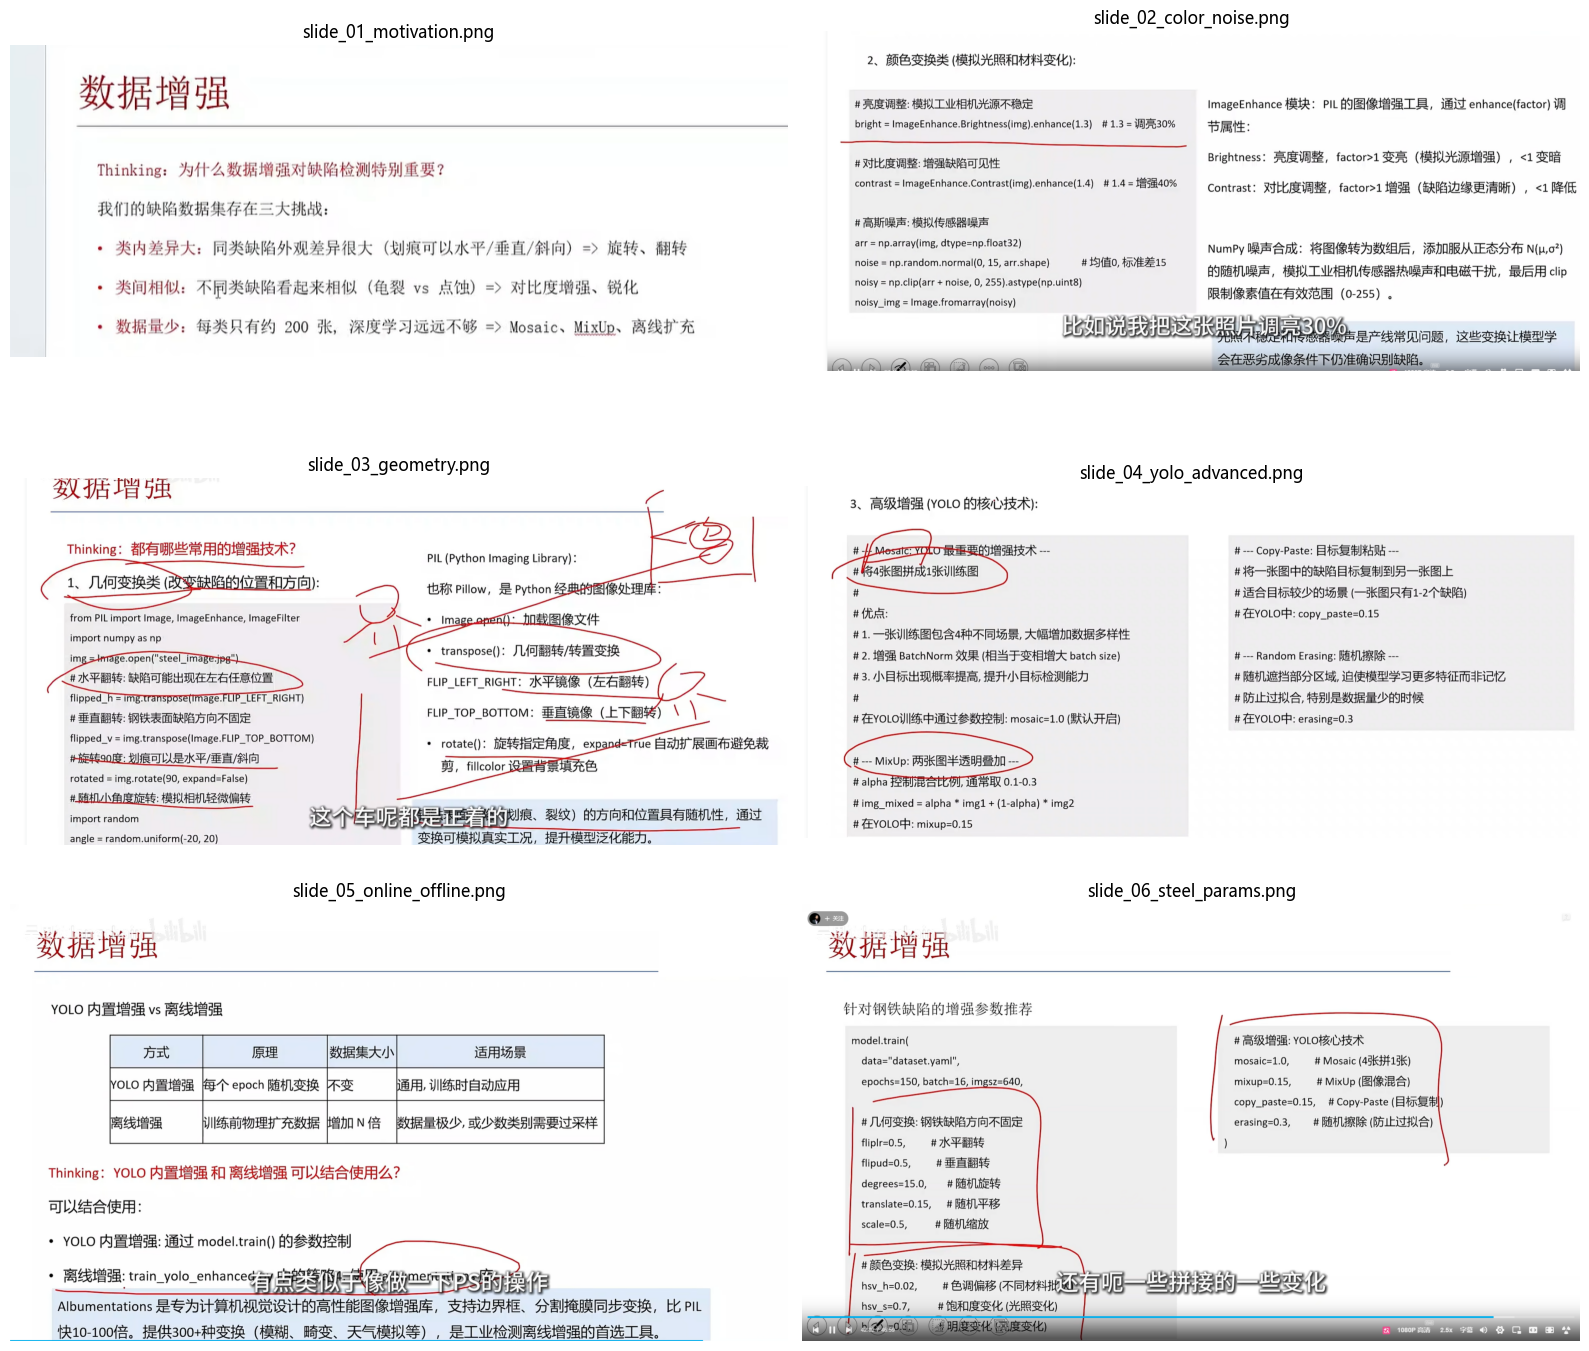

附件课件数量: 6


In [2]:
augmentation_dir = ROOT / 'courses/industrial-vision-lab/data/public/augmentation'
slide_paths = sorted(augmentation_dir.glob('slide_*.png'))
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for ax, path in zip(axes.flat, slide_paths):
    ax.imshow(Image.open(path)); ax.set_title(path.name); ax.axis('off')
plt.tight_layout(); plt.show()
print('附件课件数量:', len(slide_paths))

## 2. 真实工业原图：所有增强都从这里开始

使用公开 KolektorSDD 钢铁表面样例作为教学输入。它是真实工业表面照片；下面的增强结果是派生图，不能当成新的独立验收样本。对于动力电池汇流排，实际项目还要使用对应的汇流排、镍片和七格标注，不能直接套用钢铁缺陷标签。

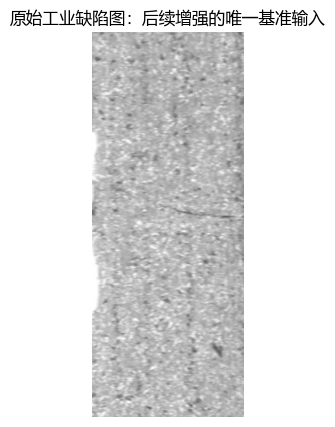

原图尺寸: (500, 1270) ；来源: D:\workspace\cv\cv-beginner-course\courses\industrial-vision-lab\data\public\kolektor\defect_0.jpg


In [3]:
base_path = ROOT / 'courses/industrial-vision-lab/data/public/kolektor/defect_0.jpg'
base = Image.open(base_path).convert('RGB')
plt.figure(figsize=(10, 5)); plt.imshow(base); plt.title('原始工业缺陷图：后续增强的唯一基准输入'); plt.axis('off'); plt.show()
print('原图尺寸:', base.size, '；来源:', base_path)

## 3. 几何增强：方向、位置和尺度变化

附件中的水平翻转、垂直翻转和旋转对应 `transpose()` 与 `rotate()`。`expand=True` 保留完整旋转画布；检测框和分割掩膜必须使用同一几何变换。

下面还用原始缺陷掩膜验证水平翻转：输入图片和掩膜执行同一变换，叠加后位置仍一致。训练集、验证集、测试集应先按物理样本分组拆分，再只增强训练集，避免数据泄漏。

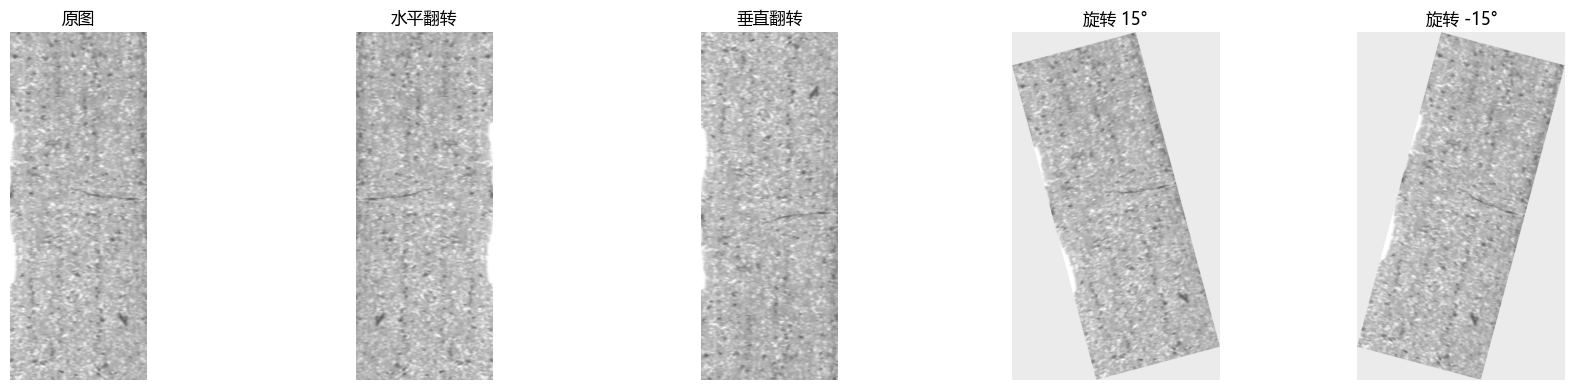

In [4]:
geom = [
    ('原图', base),
    ('水平翻转', base.transpose(Image.Transpose.FLIP_LEFT_RIGHT)),
    ('垂直翻转', base.transpose(Image.Transpose.FLIP_TOP_BOTTOM)),
    ('旋转 15°', base.rotate(15, expand=True, fillcolor=(235,235,235))),
    ('旋转 -15°', base.rotate(-15, expand=True, fillcolor=(235,235,235))),
]
fig, axes = plt.subplots(1, len(geom), figsize=(18, 4))
for ax, (title, im) in zip(axes, geom): ax.imshow(im); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

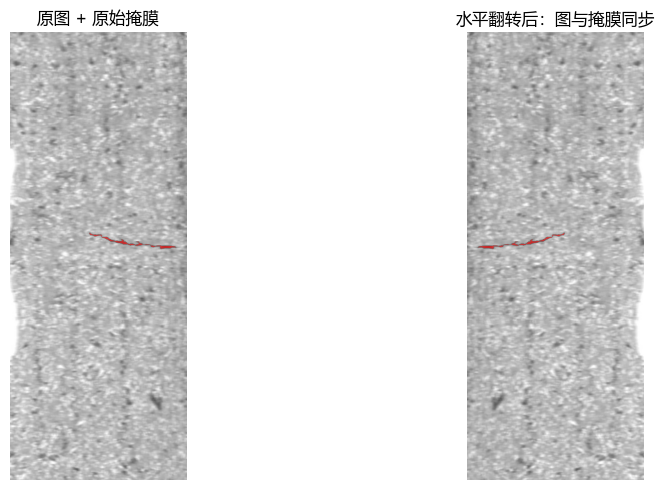

图像与掩膜尺寸: (500, 1270) (500, 1270) ；掩膜非零像素: 1143


In [5]:
mask_path = ROOT / 'courses/industrial-vision-lab/data/public/kolektor/defect_0_mask.bmp'
mask = Image.open(mask_path).convert('L')
assert mask.size == base.size, (mask.size, base.size)
image_flip = base.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
mask_flip = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, image, label, title in [(axes[0], base, mask, '原图 + 原始掩膜'), (axes[1], image_flip, mask_flip, '水平翻转后：图与掩膜同步')]:
    ax.imshow(image); ax.imshow(np.ma.masked_where(np.asarray(label) == 0, np.asarray(label)), cmap='autumn', alpha=.6); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
print('图像与掩膜尺寸:', base.size, mask.size, '；掩膜非零像素:', int(np.count_nonzero(mask)))

## 4. 颜色与噪声增强：模拟光照、材料差异和传感器噪声

附件示例使用亮度 `1.3`、对比度 `1.4`，并添加均值 0、标准差 15 的高斯噪声，再用 `clip(0,255)` 限制像素。参数只是教学起点，不能代替真实暗光和光谱标定。

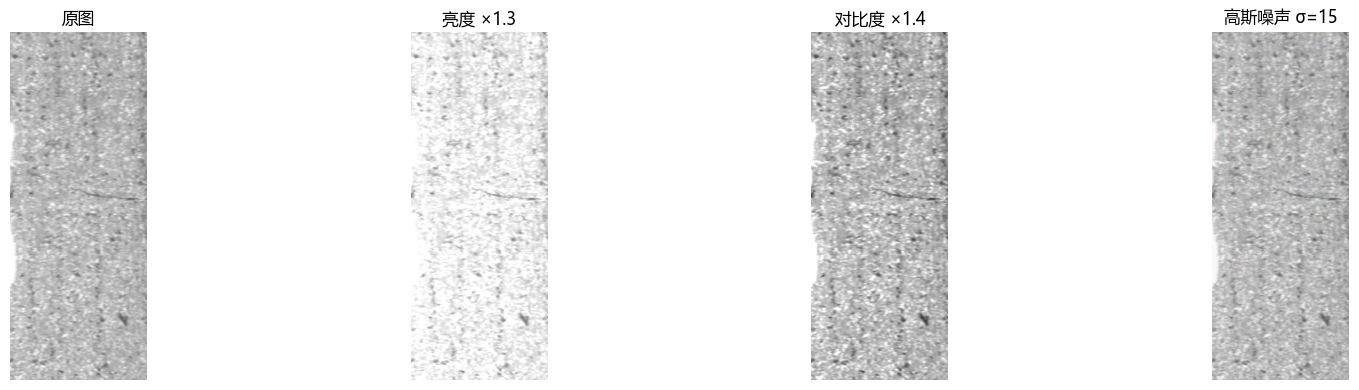

In [6]:
from PIL import ImageEnhance
bright = ImageEnhance.Brightness(base).enhance(1.3)
contrast = ImageEnhance.Contrast(base).enhance(1.4)
arr = np.asarray(base).astype(np.float32)
noise = np.random.default_rng(42).normal(0, 15, arr.shape)
noisy = Image.fromarray(np.clip(arr + noise, 0, 255).astype(np.uint8))
views = [('原图', base), ('亮度 ×1.3', bright), ('对比度 ×1.4', contrast), ('高斯噪声 σ=15', noisy)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, im) in zip(axes, views): ax.imshow(im); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Mosaic、MixUp、Copy-Paste 和 Random Erasing

- **Mosaic**：把 4 张图拼成 1 张，扩大背景、尺度和位置组合；检测框要按拼接偏移同步移动。
- **MixUp**：按 `alpha` 做两张图的透明混合，分类标签也要按比例混合；检测任务要谨慎处理重叠框。
- **Copy-Paste**：复制带实例掩膜的目标，再粘贴到另一张图；只有矩形裁剪时不能声称是实例 Copy-Paste。
- **Random Erasing**：随机擦除局部，迫使模型利用更多上下文；不能把关键焊点全部擦掉。

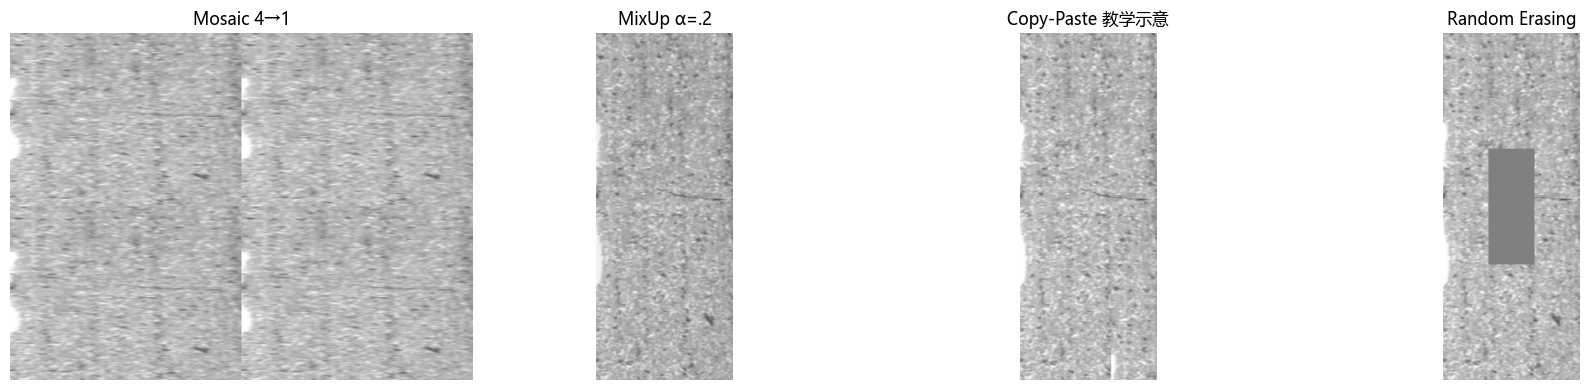

当前 Copy-Paste 使用矩形 patch 仅作流程演示，真实检测必须使用实例掩膜。


In [7]:
def fit_size(im, size=(256, 192)):
    return im.resize(size, Image.Resampling.BILINEAR)

small = fit_size(base)
mosaic = Image.new('RGB', (512, 384), (235,235,235))
for x, y in [(0,0), (256,0), (0,192), (256,192)]: mosaic.paste(small, (x,y))
other = ImageEnhance.Brightness(base).enhance(.75).resize(base.size)
mixup = Image.blend(base, other, .2)
copy_paste = base.copy(); patch = base.crop((0, 0, base.width//3, base.height//3)); copy_paste.paste(patch, (copy_paste.width*2//3, copy_paste.height*2//3))
erased = base.copy(); draw = ImageDraw.Draw(erased); draw.rectangle((base.width//3, base.height//3, base.width*2//3, base.height*2//3), fill=(128,128,128))
views = [('Mosaic 4→1', mosaic), ('MixUp α=.2', mixup), ('Copy-Paste 教学示意', copy_paste), ('Random Erasing', erased)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, im) in zip(axes, views): ax.imshow(im); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
print('当前 Copy-Paste 使用矩形 patch 仅作流程演示，真实检测必须使用实例掩膜。')

## 6. YOLO 内置增强与离线增强如何组合

YOLO 内置增强在每个 epoch 训练时随机生成，不增加磁盘样本数；离线增强在训练前生成并保存派生数据，适合样本极少或需要审计每张增强图的场景。工业检测常用组合是：离线生成少量可追溯样本，训练时再用较温和的内置增强。

Albumentations 等工具可以同时变换图像、边界框和掩膜；本课不强制安装它，先用 Pillow/NumPy 理解原理。

In [8]:
recipe = {
    'epochs': 150, 'batch': 16, 'imgsz': 640,
    'fliplr': 0.5, 'flipud': 0.5, 'degrees': 15.0,
    'translate': 0.15, 'scale': 0.5,
    'hsv_h': 0.02, 'hsv_s': 0.7, 'hsv_v': 0.4,
    'mosaic': 1.0, 'mixup': 0.15, 'copy_paste': 0.15, 'erasing': 0.3,
}
for key, value in recipe.items(): print(f'{key:>12}: {value}')
print('这些是钢铁缺陷教学起点，不是动力电池焊点的最终生产参数。')

      epochs: 150
       batch: 16
       imgsz: 640
      fliplr: 0.5
      flipud: 0.5
     degrees: 15.0
   translate: 0.15
       scale: 0.5
       hsv_h: 0.02
       hsv_s: 0.7
       hsv_v: 0.4
      mosaic: 1.0
       mixup: 0.15
  copy_paste: 0.15
     erasing: 0.3
这些是钢铁缺陷教学起点，不是动力电池焊点的最终生产参数。


### 训练接口示意及适用范围

附件中的数值是某个钢铁缺陷实验的示例，并非所有 YOLO 版本和任务都适用。下方只是代码模板，不会自动安装依赖或启动训练。请先核对所用版本的官方参数文档、数据格式和任务类型：例如 `copy_paste` 通常针对分割任务，`erasing` 的适用范围也取决于版本和任务。截图底部被遮挡的参数不臆测；`data` 和权重路径应由自己的数据集替换。

In [9]:
# 可选：准备好标注数据、安装并核对所用 Ultralytics 版本后，再取消注释。
# from ultralytics import YOLO
# model = YOLO('你的检测模型权重.pt')
# model.train(data='你的数据集.yaml', epochs=150, batch=16, imgsz=640,
#             fliplr=0.5, degrees=15.0, translate=0.15, scale=0.5,
#             hsv_h=0.02, hsv_s=0.7, mosaic=1.0, mixup=0.15)
# copy_paste 和 erasing 请先核对任务类型及版本支持，验证集保持原始分布。

## 7. 应用到汇流排焊接检测时的边界

对动力电池刀片电芯，增强必须遵循目标层级：整帧 → 汇流排 → 镍片 → 七个焊接格。可以增强亮度、暗光、轻微旋转和遮挡，但不能凭空复制焊点或把七格标签错位。每片七格中的未知状态仍应输出黄色待复核；至少五格明确合格才进入绿色通过。

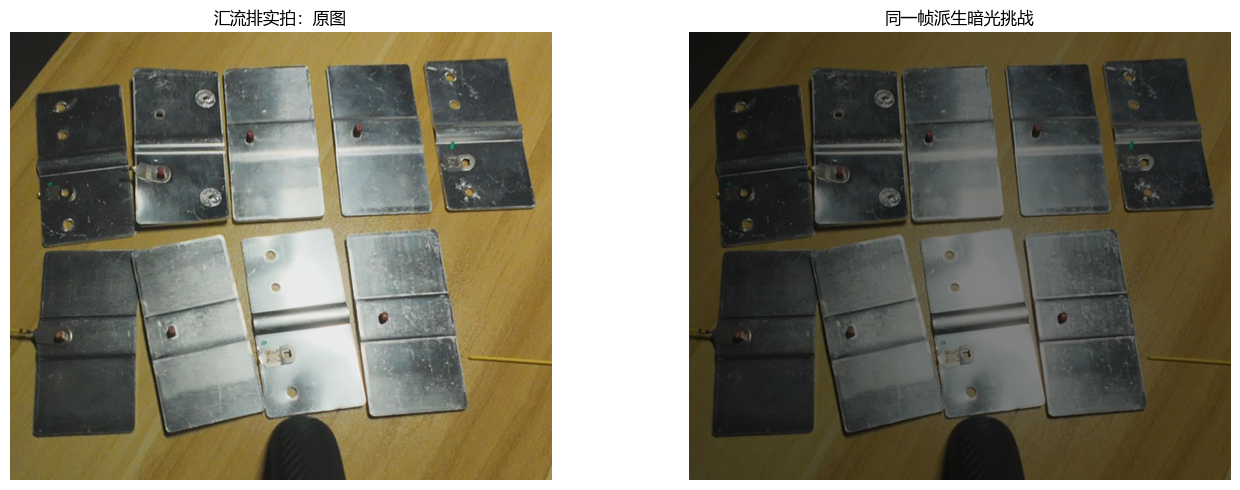

现场候选框不是人工真值，增强图也不产生新的七格标签。


In [10]:
busbar_path = ROOT / 'courses/industrial-vision-lab/data/authorized_onsite/osmo_20261117T212335Z/workpieces.png'
if busbar_path.exists():
    busbar = Image.open(busbar_path).convert('RGB')
    busbar_dark = ImageEnhance.Brightness(busbar).enhance(.55)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5)); axes[0].imshow(busbar); axes[0].set_title('汇流排实拍：原图'); axes[1].imshow(busbar_dark); axes[1].set_title('同一帧派生暗光挑战')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()
    print('现场候选框不是人工真值，增强图也不产生新的七格标签。')
else: print('未找到授权现场图，跳过现场增强示例。')

## 8. 练习与结论

1. 将旋转角从 ±15° 改为 ±5°，观察工业表面纹理是否更接近原始分布。
2. 将噪声标准差从 15 改为 30，记录边缘检测和缺陷可见性的变化。
3. 思考为什么 Copy-Paste 需要实例掩膜，为什么七格焊接不能直接用普通焊缝图片增强。

增强的目标是覆盖合理的成像变化，而不是把任何变换都堆上去。最终参数必须在独立验证集和真实补光条件下复核。